# So sánh 3 CNN tự xây dựng — Augmented Banana Ripeness
Một notebook chạy tuần tự A → B → C, dùng cùng manifest và lịch huấn luyện. Không tải pretrained weights.

- **A_slide:** theo code trang 51/74 bài giảng: Conv6(5×5,same), Pool, Conv16(5×5,valid), Pool, Flatten, Dense120, Dense84, Softmax4. Đổi đầu vào sang RGB với kích thước chung; không phải sao chép nguyên mẫu MNIST.
- **B_features:** Conv32/64/128 (3×3,same), mỗi Conv có ReLU + Pool; GAP, Dense128, Softmax4.
- **C_bn_dropout:** cùng B, thêm BN trước ReLU ở ba Conv và Dropout0.2 sau Dense128. Không thêm độ sâu hoặc SpatialDropout để so sánh B–C rõ ràng.

Mặc định ảnh 128×128 cho cả ba để hạn chế phần Flatten của A; có thể chọn256 trước khi chạy tất cả. Không so trực tiếp điểm mới với các lần256 cũ để quy kết tác dụng kiến trúc.

Chọn TRAIN_SEEDS=[42] để chạy thử3 lượt; [42,43,44] để chạy9 lượt. MODEL_NAMES chọn các model muốn chạy. Test mặc định tắt. Restart kernel rồi Run All khi bắt đầu thí nghiệm mới. Mỗi lần Run All tạo thư mục kết quả riêng.


In [1]:
import os, json, random, time, gc, hashlib, shutil
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

tf.config.experimental.enable_op_determinism()
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
DATA_ROOT = None  # Thư mục chứa trực tiếp Green, Semi-ripe, Ripe, Overripe
MANIFEST_CSV = None  # Khuyên dùng manifest_used.csv của dataset chuối hiện tại
SPLIT_SEED = 42
TRAIN_SEEDS = [42]  # Đổi thành [42, 43, 44] để đo ổn định
MODEL_NAMES = ["A_slide", "B_features", "C_bn_dropout"]
IMAGE_SIZE = (128, 128)  # Cùng kích thước cho cả3; có thể chọn (256,256)
CLASS_NAMES = ["Green", "Semi-ripe", "Ripe", "Overripe"]
SPLIT_RATIOS = (0.70, 0.15, 0.15)
BATCH_SIZE = 32
LEARNING_RATE = 3e-4
EPOCHS = 60
PATIENCE = 12
DROPOUT_RATE = 0.20
BN_MOMENTUM = 0.90
RUN_TEST = False
SEED = SPLIT_SEED
assert TRAIN_SEEDS and len(set(TRAIN_SEEDS)) == len(TRAIN_SEEDS)
assert MODEL_NAMES and len(set(MODEL_NAMES)) == len(MODEL_NAMES)
assert set(MODEL_NAMES) <= {"A_slide", "B_features", "C_bn_dropout"}
assert min(IMAGE_SIZE) >= 16
base_output = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
OUTPUT = base_output / ("cnn_ABC_" + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f"))
OUTPUT.mkdir(parents=True, exist_ok=False)
if DATA_ROOT is None:
    candidates = sorted({p.parent.resolve() for p in Path("/kaggle/input").rglob("Green")
                         if p.is_dir() and all((p.parent / label).is_dir() for label in CLASS_NAMES)})
    if len(candidates) != 1:
        raise ValueError(f"Cần đặt DATA_ROOT; tìm thấy {candidates}")
    DATA_ROOT = candidates[0]
DATA_ROOT = Path(DATA_ROOT).resolve()
assert all((DATA_ROOT / label).is_dir() for label in CLASS_NAMES), "DATA_ROOT không đúng dataset4 lớp"
print("Dataset:", DATA_ROOT)
print("Kết quả:", OUTPUT)


Dataset: /kaggle/input/datasets/thinhng04/banana-dataset/Augmented Banana Ripeness Detection Dataset/Augmented Banana Ripeness Detection Dataset
Kết quả: /kaggle/working/cnn_ABC_20261103_015908_347751


## Manifest dùng chung
Giữ các biến thể có cùng tên trước `.rf.` trong cùng split. Đây là nhóm theo tên, không phải xác nhận độc lập theo mẫu vật. Nếu MANIFEST_CSV=None, tái tạo cách chia bằng thuật toán baseline trên đúng danh sách ảnh. Không thay nhãn.


In [3]:
label_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}

def source_id(path):
    # Không thêm nhãn vào group: cùng tên nguồn ở hai lớp cũng cần kiểm tra.
    return Path(path).name.split(".rf.")[0]

def assign_group_splits(frame):
    frame = frame.copy()
    frame["source_id"] = frame.path.map(source_id)
    conflicts = frame.groupby("source_id").label.nunique()
    assert not (conflicts > 1).any(), "Có tên nguồn xuất hiện ở nhiều lớp; cần rà soát trước khi chia."
    rng = np.random.default_rng(SEED)
    mapping = {}
    for label in CLASS_NAMES:
        groups = np.array(sorted(frame.loc[frame.label == label, "source_id"].unique()))
        assert len(groups) >= 7, f"Quá ít nhóm ảnh nguồn cho lớp {label}"
        rng.shuffle(groups)
        n_train = int(len(groups) * SPLIT_RATIOS[0])
        n_valid = int(len(groups) * SPLIT_RATIOS[1])
        for split, part in zip(["train", "valid", "test"],
                               [groups[:n_train], groups[n_train:n_train+n_valid], groups[n_train+n_valid:]]):
            mapping.update({str(g): split for g in part})
    frame["split"] = frame.source_id.map(mapping)
    return frame

if MANIFEST_CSV:
    df = pd.read_csv(MANIFEST_CSV)
    assert {"path", "label", "split"}.issubset(df.columns), "CSV cần path,label,split"
    df = df[["path", "label", "split"]].copy()
    assert not df.isna().any().any(), "Manifest có giá trị thiếu"
    df["path"] = df.path.map(lambda p: str((DATA_ROOT / str(p)).resolve()))
    df["source_id"] = df.path.map(source_id)
else:
    extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
    rows = [{"path": str(p.resolve()), "label": label}
            for label in CLASS_NAMES for p in sorted((DATA_ROOT / label).rglob("*"))
            if p.is_file() and p.suffix.lower() in extensions]
    df = pd.DataFrame(rows, columns=["path", "label"])
    assert len(df), "Không tìm thấy ảnh"
    df = assign_group_splits(df)
assert len(df), "Manifest rỗng"
assert set(df.label) == set(CLASS_NAMES), f"Nhãn không khớp: {sorted(df.label.unique())}"
assert set(df.split) == {"train", "valid", "test"}, "Cần đủ train/valid/test"
assert not df.path.duplicated().any(), "Đường dẫn ảnh bị lặp"
assert (df.groupby("source_id").split.nunique() == 1).all(), "Rò rỉ nhóm tên nguồn giữa các split"
assert (df.groupby("source_id").label.nunique() == 1).all(), "Cùng tên nguồn nhưng khác nhãn"
missing = [p for p in df.path if not Path(p).is_file()]
assert not missing, f"Không tìm thấy ảnh: {missing[:3]}"
counts = pd.crosstab(df.label, df.split).reindex(index=CLASS_NAMES, columns=["train", "valid", "test"], fill_value=0)
assert (counts > 0).all().all(), "Mỗi split cần đủ 4 lớp"
df["label_id"] = df.label.map(label_to_id)
df = df.sort_values(["split", "label_id", "path"]).reset_index(drop=True)
print("Số ảnh theo lớp/split:")
display(counts)
print("Số nhóm nguồn:")
display(df.groupby(["label", "split"]).source_id.nunique().unstack().reindex(CLASS_NAMES))
print("Thứ tự nhãn:", label_to_id)
print("Chia theo tên nguồn; chưa kiểm tra gần trùng giữa các tên khác nhau.")
# Lưu đường dẫn tương đối để cả nhóm có thể dùng lại trên Kaggle.
manifest = df.copy()
manifest["path"] = manifest.path.map(lambda p: Path(p).relative_to(DATA_ROOT).as_posix())
manifest.to_csv(OUTPUT / "manifest_used.csv", index=False)
(OUTPUT / "class_names.json").write_text(json.dumps(CLASS_NAMES, ensure_ascii=False, indent=2), encoding="utf-8")

records = manifest[["path", "label", "split"]].sort_values("path").to_csv(index=False, lineterminator="\n")
SPLIT_SHA = hashlib.sha256(records.encode("utf-8")).hexdigest()
config = dict(data_root=str(DATA_ROOT), manifest_csv=str(MANIFEST_CSV) if MANIFEST_CSV else None,
    split_sha256=SPLIT_SHA, split_seed=SPLIT_SEED, train_seeds=TRAIN_SEEDS, models=MODEL_NAMES,
    image_size=list(IMAGE_SIZE), batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE,
    max_epochs=EPOCHS, early_stopping_patience=PATIENCE, monitor="val_loss",
    lr_scheduler=dict(factor=0.5, patience=4, min_lr=1e-6, min_delta=0.),
    dropout_C=DROPOUT_RATE, bn_momentum_C=BN_MOMENTUM,
    preprocessing="EXIF RGB, bilinear letterbox black padding, model Rescaling 1/255",
    online_augmentation=False, deterministic_ops=True, tensorflow=tf.__version__)
(OUTPUT / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Split fingerprint:", SPLIT_SHA)


Số ảnh theo lớp/split:


split,train,valid,test
label,,,
Green,444,93,99
Semi-ripe,426,90,93
Ripe,420,90,93
Overripe,426,90,93


Số nhóm nguồn:


split,test,train,valid
label,,,
Green,33,148,31
Semi-ripe,31,142,30
Ripe,31,140,30
Overripe,31,142,30


Thứ tự nhãn: {'Green': 0, 'Semi-ripe': 1, 'Ripe': 2, 'Overripe': 3}
Chia theo tên nguồn; chưa kiểm tra gần trùng giữa các tên khác nhau.
Split fingerprint: fd00e11b0028b8dd68fa9d3441d4e5f14f2cfe62cb853d316148318efb6e47fb


In [4]:
def read_rgb_numpy(path):
    path = path.item() if hasattr(path, "item") else path
    path = path.decode("utf-8") if isinstance(path, bytes) else str(path)
    with Image.open(path) as im:
        return np.asarray(ImageOps.exif_transpose(im).convert("RGB"), dtype=np.uint8)

def load_image(path, label):
    image = tf.numpy_function(read_rgb_numpy, [path], tf.uint8)
    image.set_shape([None, None, 3])
    image = tf.image.resize_with_pad(tf.cast(image, tf.float32), *IMAGE_SIZE,
                                    method="bilinear", antialias=True)
    image = tf.ensure_shape(image, [*IMAGE_SIZE, 3])
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False, seed=42):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.to_numpy(dtype=str), frame.label_id.to_numpy(dtype=np.int32)))
    if training:
        ds = ds.shuffle(len(frame), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE, deterministic=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_df = df[df.split.eq("train")].reset_index(drop=True)
valid_df = df[df.split.eq("valid")].reset_index(drop=True)


## Kiến trúc
A→B kiểm tra một gói thay đổi kiến trúc, không tách tác dụng từng thành phần. B→C kiểm tra gói BN+Dropout, không kết luận tác dụng riêng của BN hay Dropout. Model A ít Conv nhưng có thể nhiều tham số do Flatten. Code sẽ in số tham số trước khi train.


In [5]:
L = tf.keras.layers

def build_model(name):
    inputs = L.Input(shape=(*IMAGE_SIZE, 3), name="rgb_image")
    x = L.Rescaling(1./255., name="normalize")(inputs)
    if name == "A_slide":
        x = L.Conv2D(6, 5, padding="same", activation="relu", name="conv1")(x)
        x = L.MaxPooling2D(2)(x)
        x = L.Conv2D(16, 5, padding="valid", activation="relu", name="conv2")(x)
        x = L.MaxPooling2D(2)(x)
        x = L.Flatten()(x)
        x = L.Dense(120, activation="relu")(x)
        x = L.Dense(84, activation="relu")(x)
    elif name in {"B_features", "C_bn_dropout"}:
        for i, filters in enumerate([32, 64, 128], 1):
            # C tắt bias Conv vì BN đã có tham số dịch beta.
            x = L.Conv2D(filters, 3, padding="same", use_bias=name != "C_bn_dropout",
                         name=f"conv{i}")(x)
            if name == "C_bn_dropout":
                x = L.BatchNormalization(momentum=BN_MOMENTUM, name=f"bn{i}")(x)
            x = L.ReLU()(x)
            x = L.MaxPooling2D(2)(x)
        x = L.GlobalAveragePooling2D()(x)
        x = L.Dense(128, activation="relu")(x)
        if name == "C_bn_dropout":
            x = L.Dropout(DROPOUT_RATE)(x)
    else:
        raise ValueError(name)
    outputs = L.Dense(4, activation="softmax", name="probabilities")(x)
    return tf.keras.Model(inputs, outputs, name=name)

architecture_rows = []
for name in MODEL_NAMES:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(TRAIN_SEEDS[0])
    probe_model = build_model(name)
    probe = probe_model(tf.zeros((2, *IMAGE_SIZE, 3)), training=False).numpy()
    assert probe.shape == (2, 4) and np.isfinite(probe).all()
    np.testing.assert_allclose(probe.sum(axis=1), 1., atol=1e-5)
    architecture_rows.append(dict(model=name, parameters=probe_model.count_params()))
    (OUTPUT / f"{name}_architecture.json").write_text(probe_model.to_json(), encoding="utf-8")
    with (OUTPUT / f"{name}_summary.txt").open("w", encoding="utf-8") as f:
        probe_model.summary(print_fn=lambda line, **kwargs: f.write(line+"\n"))
    del probe_model
architecture_df = pd.DataFrame(architecture_rows)
display(architecture_df)


,model,parameters
0,A_slide,1741496
1,B_features,110276
2,C_bn_dropout,110948


In [6]:
def evaluate_model(model, frame, split, run_dir):
    probs = model.predict(make_dataset(frame), verbose=0)
    truth = frame.label_id.to_numpy()
    guessed = probs.argmax(axis=1)
    report = classification_report(truth, guessed, labels=range(4), target_names=CLASS_NAMES,
                                   output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(run_dir / f"{split}_classification_report.csv")
    predictions = frame[["path", "label", "source_id"]].copy()
    predictions["path"] = predictions.path.map(lambda p: Path(p).relative_to(DATA_ROOT).as_posix())
    predictions["predicted_label"] = [CLASS_NAMES[i] for i in guessed]
    for i, label in enumerate(CLASS_NAMES): predictions[f"prob_{label}"] = probs[:, i]
    predictions.to_csv(run_dir / f"{split}_predictions.csv", index=False)
    cm = confusion_matrix(truth, guessed, labels=range(4))
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(run_dir / f"{split}_confusion_matrix.csv")
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{run_dir.name} — {split}; image counts")
    fig.tight_layout(); fig.savefig(run_dir / f"{split}_confusion_matrix.png", dpi=140)
    plt.show(); plt.close(fig)
    metrics = dict(accuracy=float(accuracy_score(truth, guessed)),
                   macro_f1=float(f1_score(truth, guessed, average="macro", labels=range(4))),
                   images=len(frame), split=split)
    for label in CLASS_NAMES: metrics[f"recall_{label}"] = report[label]["recall"]
    (run_dir / f"{split}_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print(classification_report(truth, guessed, labels=range(4), target_names=CLASS_NAMES, digits=4, zero_division=0))
    return metrics


## Huấn luyện tuần tự và đánh giá validation
Mỗi model/seed xây mới trọng số, optimizer và dataset shuffle. Từng lượt lưu checkpoint riêng. Lịch huấn luyện giống nhau nhưng số epoch thực tế có thể khác do early stopping. Thời gian fit bao gồm khởi tạo graph và lưu checkpoint, không phải benchmark suy luận.



Training A_slide, seed=42
Epoch 1/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 149s 3s/step - accuracy: 0.5449 - loss: 1.2162 - val_accuracy: 0.6088 - val_loss: 0.9840 - learning_rate: 3.0000e-04
Epoch 2/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 112ms/step - accuracy: 0.7698 - loss: 0.6514 - val_accuracy: 0.7493 - val_loss: 0.6753 - learning_rate: 3.0000e-04
Epoch 3/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 116ms/step - accuracy: 0.8333 - loss: 0.4340 - val_accuracy: 0.7769 - val_loss: 0.5699 - learning_rate: 3.0000e-04
Epoch 4/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 116ms/step - accuracy: 0.8514 - loss: 0.3603 - val_accuracy: 0.8017 - val_loss: 0.5294 - learning_rate: 3.0000e-04
Epoch 5/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 116ms/step - accuracy: 0.8811 - loss: 0.3105 - val_accuracy: 0.8209 - val_loss: 0.5130 - learning_rate: 3.0000e-04
Epoch 6/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 115ms/step - accuracy: 0.9120 - loss: 0.2366 - val_accuracy: 0.7631 - val_loss: 0.5719 - learning_rate: 3.0000e-04
Epoch 7/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 

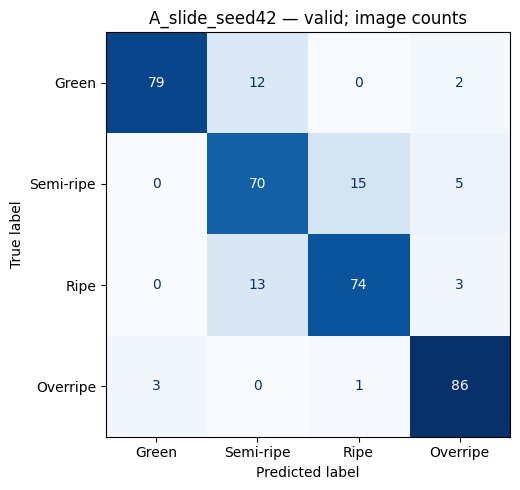

              precision    recall  f1-score   support

       Green     0.9634    0.8495    0.9029        93
   Semi-ripe     0.7368    0.7778    0.7568        90
        Ripe     0.8222    0.8222    0.8222        90
    Overripe     0.8958    0.9556    0.9247        90

    accuracy                         0.8512       363
   macro avg     0.8546    0.8513    0.8516       363
weighted avg     0.8555    0.8512    0.8521       363


Training B_features, seed=42
Epoch 1/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - accuracy: 0.2821 - loss: 1.3822 - val_accuracy: 0.4738 - val_loss: 1.3667 - learning_rate: 3.0000e-04
Epoch 2/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 125ms/step - accuracy: 0.4382 - loss: 1.2715 - val_accuracy: 0.6309 - val_loss: 1.1389 - learning_rate: 3.0000e-04
Epoch 3/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 125ms/step - accuracy: 0.6451 - loss: 0.9714 - val_accuracy: 0.7163 - val_loss: 0.8230 - learning_rate: 3.0000e-04
Epoch 4/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 122ms/step - accuracy: 0.7

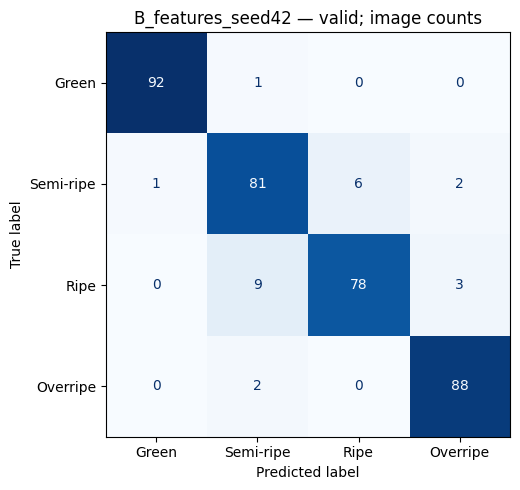

              precision    recall  f1-score   support

       Green     0.9892    0.9892    0.9892        93
   Semi-ripe     0.8710    0.9000    0.8852        90
        Ripe     0.9286    0.8667    0.8966        90
    Overripe     0.9462    0.9778    0.9617        90

    accuracy                         0.9339       363
   macro avg     0.9338    0.9334    0.9332       363
weighted avg     0.9342    0.9339    0.9337       363


Training C_bn_dropout, seed=42
Epoch 1/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 145ms/step - accuracy: 0.6533 - loss: 0.9447 - val_accuracy: 0.7300 - val_loss: 0.8206 - learning_rate: 3.0000e-04
Epoch 2/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 141ms/step - accuracy: 0.8572 - loss: 0.5167 - val_accuracy: 0.8127 - val_loss: 0.4830 - learning_rate: 3.0000e-04
Epoch 3/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 141ms/step - accuracy: 0.8695 - loss: 0.4031 - val_accuracy: 0.8595 - val_loss: 0.4074 - learning_rate: 3.0000e-04
Epoch 4/60
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 140ms/step - accuracy: 

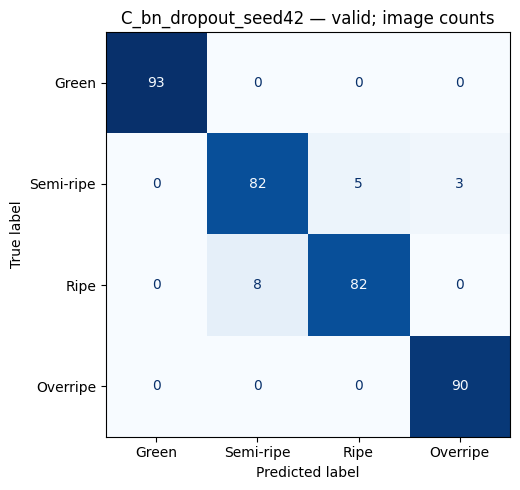

              precision    recall  f1-score   support

       Green     1.0000    1.0000    1.0000        93
   Semi-ripe     0.9111    0.9111    0.9111        90
        Ripe     0.9425    0.9111    0.9266        90
    Overripe     0.9677    1.0000    0.9836        90

    accuracy                         0.9559       363
   macro avg     0.9553    0.9556    0.9553       363
weighted avg     0.9557    0.9559    0.9557       363



In [7]:
results = []
for seed in TRAIN_SEEDS:
    for name in MODEL_NAMES:
        tf.keras.backend.clear_session(); gc.collect()
        tf.keras.utils.set_random_seed(seed)
        run_dir = OUTPUT / f"{name}_seed{seed}"
        run_dir.mkdir(exist_ok=False)
        model = build_model(name)
        model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
                      loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        train_ds = make_dataset(train_df, training=True, seed=seed)
        valid_ds = make_dataset(valid_df)
        callbacks = [
            tf.keras.callbacks.ModelCheckpoint(str(run_dir / "best_model.keras"), monitor="val_loss", mode="min", save_best_only=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_delta=0., min_lr=1e-6, verbose=1),
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1),
            tf.keras.callbacks.CSVLogger(str(run_dir / "training_log.csv")),
            tf.keras.callbacks.TerminateOnNaN()]
        print(f"\nTraining {name}, seed={seed}")
        start = time.perf_counter()
        history = model.fit(train_ds, validation_data=valid_ds, epochs=EPOCHS, callbacks=callbacks)
        seconds = time.perf_counter() - start
        hist = pd.DataFrame(history.history)
        hist.index = np.arange(1, len(hist)+1); hist.index.name = "epoch"
        hist.to_csv(run_dir / "history.csv")
        assert np.isfinite(hist[["loss", "val_loss"]].to_numpy()).all(), "Loss không hữu hạn; xem log"
        best_epoch = int(hist.val_loss.idxmin())
        del model
        model = tf.keras.models.load_model(run_dir / "best_model.keras")
        row = dict(model=name, seed=seed, split_sha256=SPLIT_SHA, parameters=model.count_params(),
                   best_epoch=best_epoch, epochs_run=len(hist), fit_seconds=seconds,
                   best_val_loss=float(hist.val_loss.min()), run_dir=str(run_dir))
        row.update(evaluate_model(model, valid_df, "valid", run_dir))
        (run_dir / "run_summary.json").write_text(json.dumps(row, indent=2), encoding="utf-8")
        results.append(row)
        pd.DataFrame(results).to_csv(OUTPUT / "validation_runs.csv", index=False)
        del model, train_ds, valid_ds
        gc.collect()


## So sánh kết quả
Độ lệch chuẩn mẫu tính trên các seed huấn luyện, không phải độ bất định do chia dữ liệu. Một seed không có SD (để NaN). Không chọn seed tốt nhất làm đại diện. Loss/accuracy lúc train của C chịu ảnh hưởng BN/Dropout, khác chế độ inference.


,model,seed,parameters,best_epoch,epochs_run,fit_seconds,best_val_loss,accuracy,macro_f1,images,split,recall_Green,recall_Semi-ripe,recall_Ripe,recall_Overripe
0,A_slide,42,1741496,14,26,304.883753,0.426323,0.851240,0.851642,363,valid,0.849462,0.777778,0.822222,0.955556
1,B_features,42,110276,60,60,401.818687,0.156563,0.933884,0.933198,363,valid,0.989247,0.900000,0.866667,0.977778
2,C_bn_dropout,42,110948,29,41,314.900129,0.123566,0.955923,0.955318,363,valid,1.000000,0.911111,0.911111,1.000000


,runs,parameters,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,fit_seconds_mean
model,,,,,,,
A_slide,1,1741496,0.851240,NaN,0.851642,NaN,304.883753
B_features,1,110276,0.933884,NaN,0.933198,NaN,401.818687
C_bn_dropout,1,110948,0.955923,NaN,0.955318,NaN,314.900129


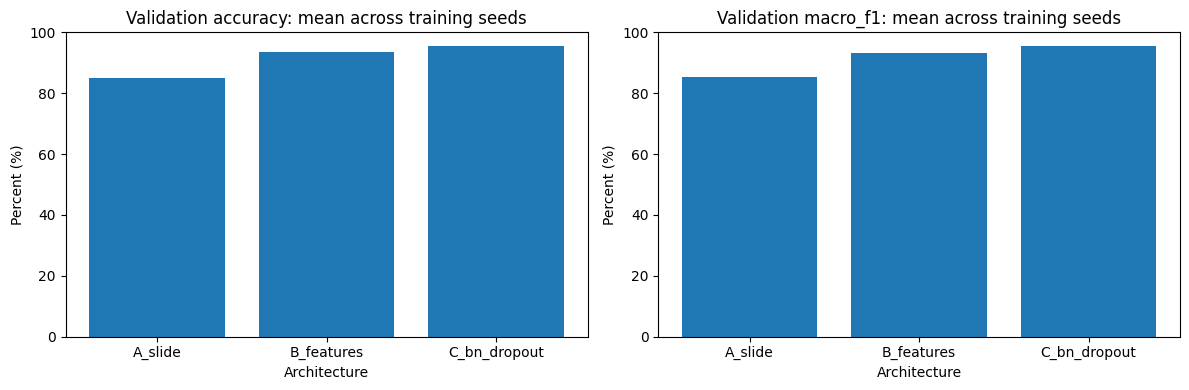

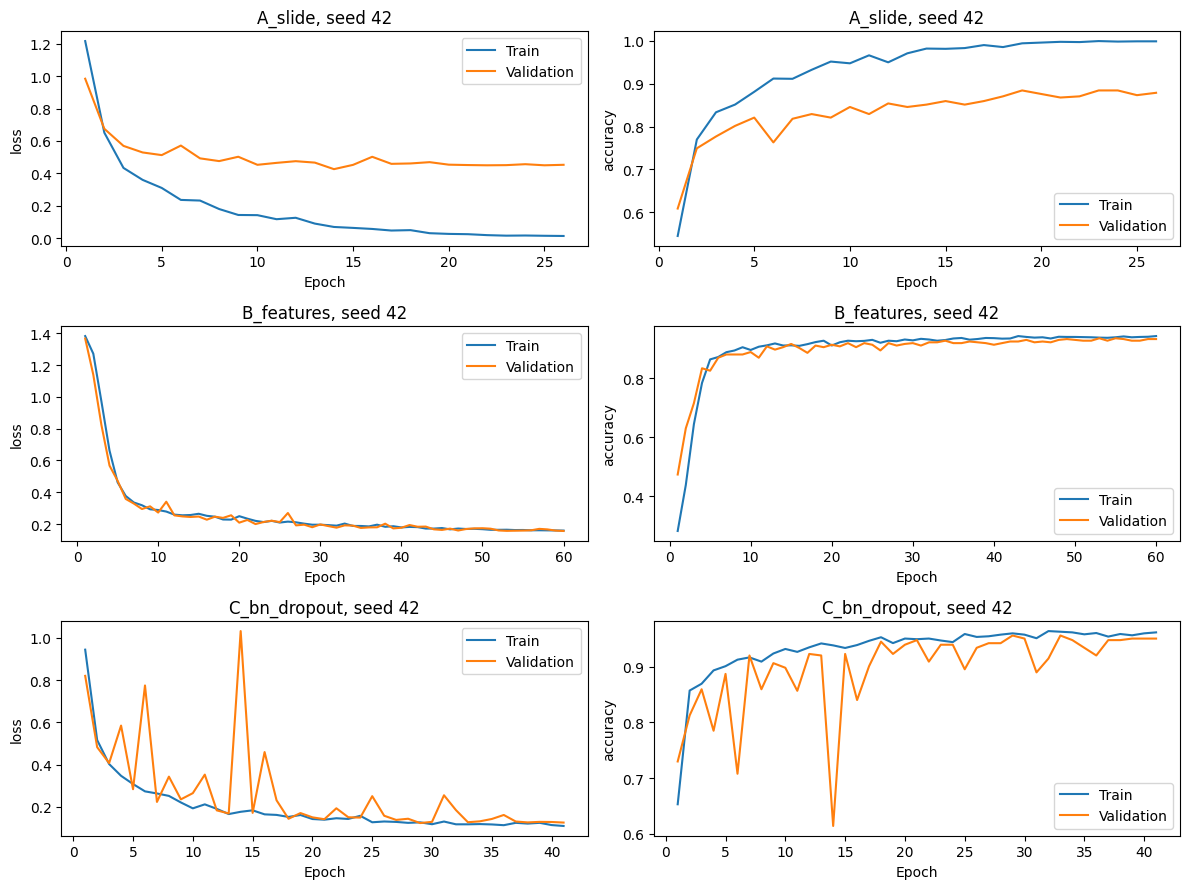

In [8]:
results_df = pd.DataFrame(results)
display(results_df.drop(columns=["run_dir", "split_sha256"]))
summary = results_df.groupby("model", sort=False).agg(
    runs=("seed", "count"), parameters=("parameters", "first"),
    accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
    macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
    fit_seconds_mean=("fit_seconds", "mean"))
summary.to_csv(OUTPUT / "validation_summary.csv")
display(summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["accuracy", "macro_f1"]):
    ax.bar(summary.index, summary[metric+"_mean"]*100)
    if (summary.runs > 1).all():
        ax.errorbar(summary.index, summary[metric+"_mean"]*100,
                    yerr=summary[metric+"_std"]*100, fmt="none", color="black", capsize=4)
    ax.set(title=f"Validation {metric}: mean across training seeds", xlabel="Architecture", ylabel="Percent (%)", ylim=(0,100))
fig.tight_layout(); fig.savefig(OUTPUT / "validation_comparison.png", dpi=160)
plt.show(); plt.close(fig)
for seed in TRAIN_SEEDS:
    fig, axes = plt.subplots(len(MODEL_NAMES), 2, figsize=(12, 3*len(MODEL_NAMES)), squeeze=False)
    for row_axes, name in zip(axes, MODEL_NAMES):
        h = pd.read_csv(OUTPUT / f"{name}_seed{seed}" / "history.csv")
        for ax, metric in zip(row_axes, ["loss", "accuracy"]):
            ax.plot(h.epoch, h[metric], label="Train")
            ax.plot(h.epoch, h["val_"+metric], label="Validation")
            ax.set(title=f"{name}, seed {seed}", xlabel="Epoch", ylabel=metric)
            ax.legend()
    fig.tight_layout(); fig.savefig(OUTPUT / f"learning_curves_seed{seed}.png", dpi=150)
    plt.show(); plt.close(fig)


## Test cuối cùng — không huấn luyện lại
Sau khi chốt các cấu hình, đổi RUN_TEST=True trong cell dưới và chỉ chạy cell này. Đánh giá tất cả checkpoint đã chạy; không chọn model/seed theo test. Nếu phiên kernel đã mất, cần khôi phục OUTPUT, manifest và các hàm trước khi dùng; không Run All chỉ để xem test. SVM/MobileNet cần cùng danh sách ảnh test để so sánh.


In [9]:
# RUN_TEST = True  # Bỏ dấu # khi đã sẵn sàng đánh giá cuối
if RUN_TEST:
    test_frame = df[df.split.eq("test")].reset_index(drop=True)
    saved_runs = pd.read_csv(OUTPUT / "validation_runs.csv")
    test_rows = []
    for item in saved_runs.itertuples():
        tf.keras.backend.clear_session()
        run_dir = OUTPUT / f"{item.model}_seed{item.seed}"
        model = tf.keras.models.load_model(run_dir / "best_model.keras")
        metrics = evaluate_model(model, test_frame, "test", run_dir)
        test_rows.append(dict(model=item.model, seed=item.seed, split_sha256=SPLIT_SHA, **metrics))
        del model; gc.collect()
    test_results = pd.DataFrame(test_rows)
    test_results.to_csv(OUTPUT / "test_runs.csv", index=False)
    test_summary = test_results.groupby("model").agg(
        runs=("seed","count"), accuracy_mean=("accuracy","mean"), accuracy_std=("accuracy","std"),
        macro_f1_mean=("macro_f1","mean"), macro_f1_std=("macro_f1","std"))
    test_summary.to_csv(OUTPUT / "test_summary.csv")
    display(test_results); display(test_summary)
else:
    print("Chưa đánh giá test.")


Chưa đánh giá test.


In [10]:
archive = shutil.make_archive(str(OUTPUT), "zip", root_dir=OUTPUT)
print("Kết quả:", OUTPUT)
print("ZIP:", archive)
# Nếu vừa chạy test sau đó, chạy lại cell này để ZIP có kết quả test.


Kết quả: /kaggle/working/cnn_ABC_20261103_015908_347751
ZIP: /kaggle/working/cnn_ABC_20261103_015908_347751.zip
